In [12]:
from pathlib import Path
import json
import csv

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sympy.ntheory.primetest import proth_test
from torch.optim.lr_scheduler import StepLR
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import numpy as np





In [13]:
# Parámetros principales del experimento
DATA_DIR = Path('./MNIST_2')
OUTPUT_DIR = Path('./resultados_mnist_convnet_2')
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints_2'
FIGURES_DIR = OUTPUT_DIR / 'figuras_2'

BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 1.0
LR_GAMMA = 0.7
SEED = 42

# Creamos carpetas de salida
OUTPUT_DIR.mkdir(exist_ok=True)
CHECKPOINT_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

In [14]:
# Selección de dispositivo: CUDA si está disponible; si no, CPU.
# En equipos Apple Silicon podría usarse 'mps' si está disponible.
if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print(device)

cuda


In [15]:

config = {
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'learning_rate': LEARNING_RATE,
    'lr_gamma': LR_GAMMA,
    'seed': SEED,
    'device': str(device),
    'architecture': 'CNN con una Conv2d de 10 filtros 28x28 y log_softmax'
}
with open(OUTPUT_DIR / 'config.json', 'w') as f:
    json.dump(config, f, indent=4)


In [16]:
train_dataset = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transforms.ToTensor())
test_dataset = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transforms.ToTensor())

train_datalaoder = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_datalaoder = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Shape train ", train_dataset.data.shape, train_dataset.targets.shape)
print("Shape test ", test_dataset.data.shape, test_dataset.targets.shape)
print("Shape imagen ", train_dataset.data[0].shape)


Shape train  torch.Size([60000, 28, 28]) torch.Size([60000])
Shape test  torch.Size([10000, 28, 28]) torch.Size([10000])
Shape imagen  torch.Size([28, 28])


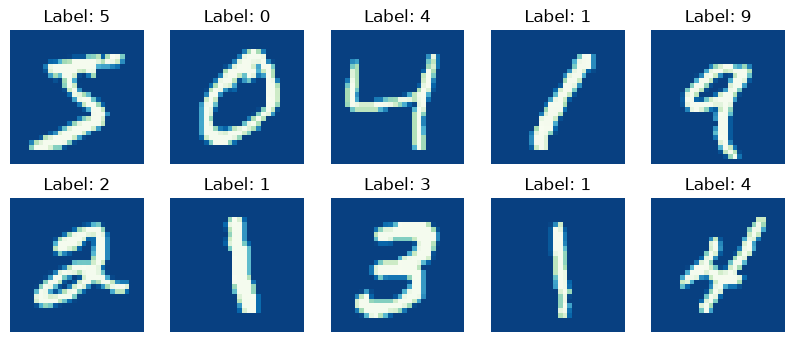

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, idx in zip(axes.ravel(), range(10)):
    img, targer = train_dataset[idx]
    ax.imshow(img.squeeze(), cmap='GnBu_r')
    ax.set_title(f'Label: {targer}')
    ax.axis('off')

plt.savefig(FIGURES_DIR / 'imagenes_mnist_2.png')
plt.show();

In [18]:
"""class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 10, kernel_size=28, bias = False)


    def forward(self, x):
        x = self.conv1(x)

        x = torch.flatten(x, 1)

        output = F.log_softmax(x, dim=1)

        return output

model = CNN()
model = model.to(device)
print(model)"""


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 10, kernel_size=3)
        self.conv2 = nn.Conv2d(10, 50, kernel_size=3)
        self.fc1 = nn.Linear(7200, 20)
        self.fc2 = nn.Linear(20, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return  F.log_softmax(x, dim=1)
model = CNN()
model = model.to(device)
print(model)

CNN(
  (conv1): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(10, 50, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=7200, out_features=20, bias=True)
  (fc2): Linear(in_features=20, out_features=10, bias=True)
)


In [19]:
def train(model, device, train_loader, optimizer, epoch):
    model.train()
    running_loss = 0.0

    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if batch_idx % 1000 == 0:
            print(
                f'Época {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} '
                f'({100. * batch_idx / len(train_loader):.0f}%)]	Pérdida: {loss.item():.6f}'
            )

    average_loss = running_loss / len(train_loader)
    return average_loss


In [20]:

def test(model, device, test_loader):
    """Evalúa el modelo sobre el conjunto de test."""
    model.eval()
    test_loss = 0.0
    correct = 0

    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)

            test_loss += F.nll_loss(output, target, reduction='sum').item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_targets.extend(target.cpu().numpy().tolist())
            all_predictions.extend(pred.squeeze().cpu().numpy().tolist())

    test_loss /= len(test_loader.dataset)
    accuracy = correct / len(test_loader.dataset)

    print(
        f'Test: pérdida media: {test_loss:.4f}, '
        f'precisión: {correct}/{len(test_loader.dataset)} '
        f'({100. * accuracy:.2f}%)'
    )

    return test_loss, accuracy, all_targets, all_predictions

In [21]:
optimizer = optim.Adadelta(model.parameters(), lr=LEARNING_RATE)
scheduler = StepLR(optimizer, step_size=1, gamma=LR_GAMMA)

loss_list = []
test_loss_list = []
accuracy_list = []
learning_rates = []

In [22]:
loss_list = []
test_loss_list = []
accuracy_list = []

for epoch in range(1, EPOCHS + 1):
    current_lr = optimizer.param_groups[0]['lr']
    learning_rates.append(current_lr)

    print(f'=== Época {epoch}/{EPOCHS} | learning rate = {current_lr:.6f} ===')

    train_loss = train(model, device, train_datalaoder, optimizer, epoch)
    test_loss, accuracy, all_targets, all_predictions = test(model, device, test_datalaoder)

    loss_list.append(train_loss)
    test_loss_list.append(test_loss)
    accuracy_list.append(accuracy)

    # Guardamos checkpoint intermedio para poder recuperar el modelo en esta época
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'train_loss': train_loss,
        'test_loss': test_loss,
        'accuracy': accuracy
    }

    torch.save(checkpoint, CHECKPOINT_DIR / f'checkpoint_epoch_{epoch:02d}.pt')

    scheduler.step()

# Guardamos el modelo final
model_path = OUTPUT_DIR / 'modelo_final_mnist_convnet.pt'
torch.save(model.state_dict(), model_path)
print(f'Modelo final guardado en: {model_path}')

=== Época 1/15 | learning rate = 1.000000 ===
Época 1 [0/60000 (0%)]	Pérdida: 2.294257
Test: pérdida media: 0.0693, precisión: 9761/10000 (97.61%)
=== Época 2/15 | learning rate = 0.700000 ===
Época 2 [0/60000 (0%)]	Pérdida: 0.042146
Test: pérdida media: 0.0451, precisión: 9854/10000 (98.54%)
=== Época 3/15 | learning rate = 0.490000 ===
Época 3 [0/60000 (0%)]	Pérdida: 0.036106
Test: pérdida media: 0.0343, precisión: 9878/10000 (98.78%)
=== Época 4/15 | learning rate = 0.343000 ===
Época 4 [0/60000 (0%)]	Pérdida: 0.030035
Test: pérdida media: 0.0331, precisión: 9884/10000 (98.84%)
=== Época 5/15 | learning rate = 0.240100 ===
Época 5 [0/60000 (0%)]	Pérdida: 0.012471
Test: pérdida media: 0.0287, precisión: 9898/10000 (98.98%)
=== Época 6/15 | learning rate = 0.168070 ===
Época 6 [0/60000 (0%)]	Pérdida: 0.000627
Test: pérdida media: 0.0291, precisión: 9893/10000 (98.93%)
=== Época 7/15 | learning rate = 0.117649 ===
Época 7 [0/60000 (0%)]	Pérdida: 0.002529
Test: pérdida media: 0.0296, pr

In [23]:
metrics_path = OUTPUT_DIR / 'metricas_entrenamiento.csv'

with open(metrics_path, 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['epoch', 'train_loss', 'test_loss', 'accuracy', 'learning_rate'])
    for i in range(EPOCHS):
        writer.writerow([i + 1, loss_list[i], test_loss_list[i], accuracy_list[i], learning_rates[i]])

print(f'Métricas guardadas en: {metrics_path}')

Métricas guardadas en: resultados_mnist_convnet_2\metricas_entrenamiento.csv


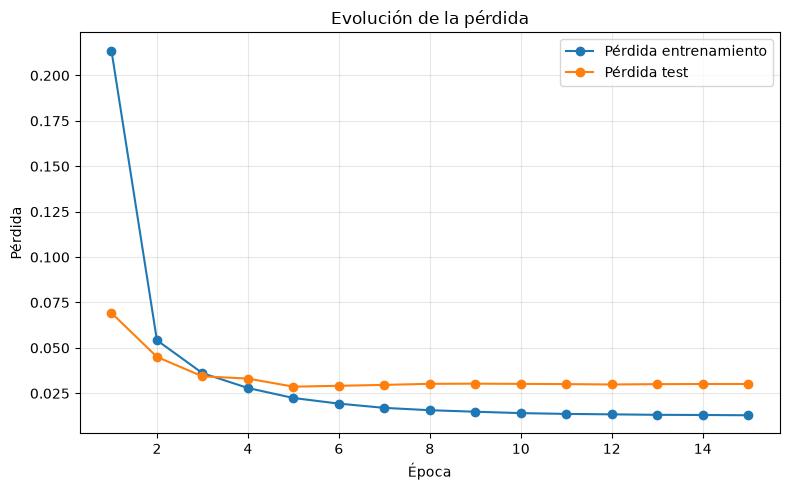

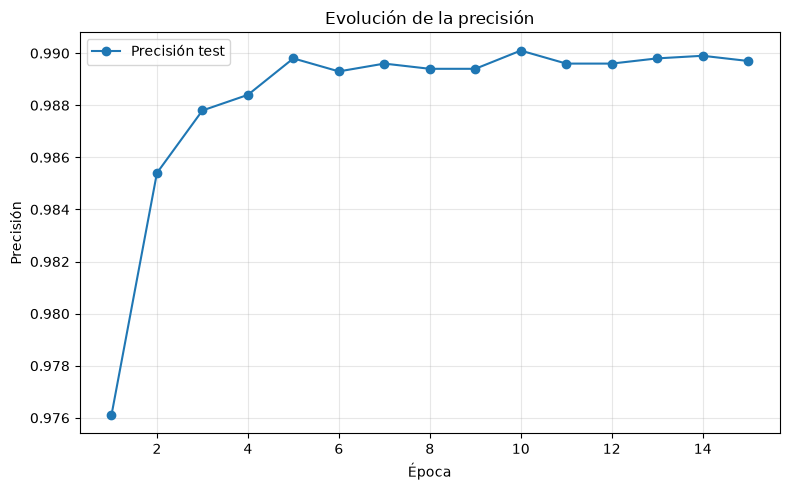

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), loss_list, marker='o', label='Pérdida entrenamiento')
plt.plot(range(1, EPOCHS + 1), test_loss_list, marker='o', label='Pérdida test')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'curva_perdida.png', dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), accuracy_list, marker='o', label='Precisión test')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.title('Evolución de la precisión')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'curva_precision.png', dpi=150)
plt.show()

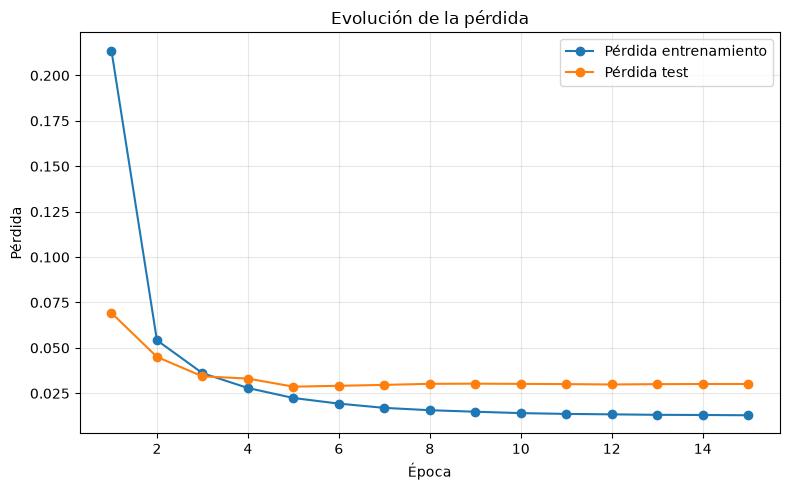

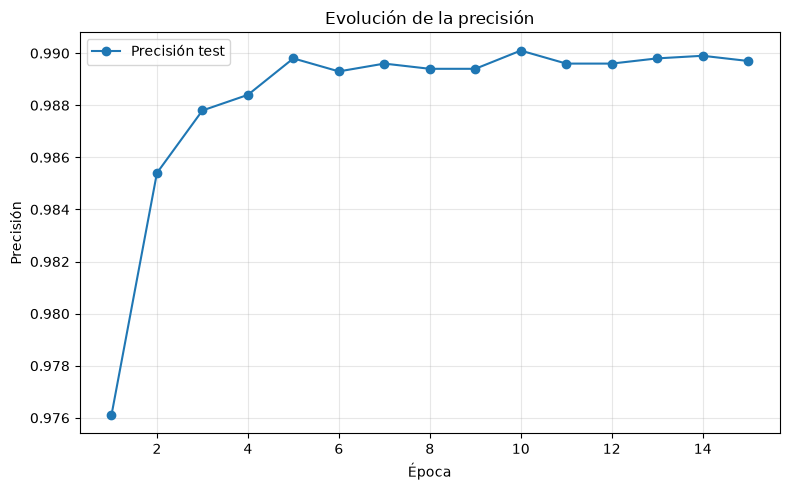

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), loss_list, marker='o', label='Pérdida entrenamiento')
plt.plot(range(1, EPOCHS + 1), test_loss_list, marker='o', label='Pérdida test')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'curva_perdida.png', dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), accuracy_list, marker='o', label='Precisión test')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.title('Evolución de la precisión')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'curva_precision.png', dpi=150)
plt.show()

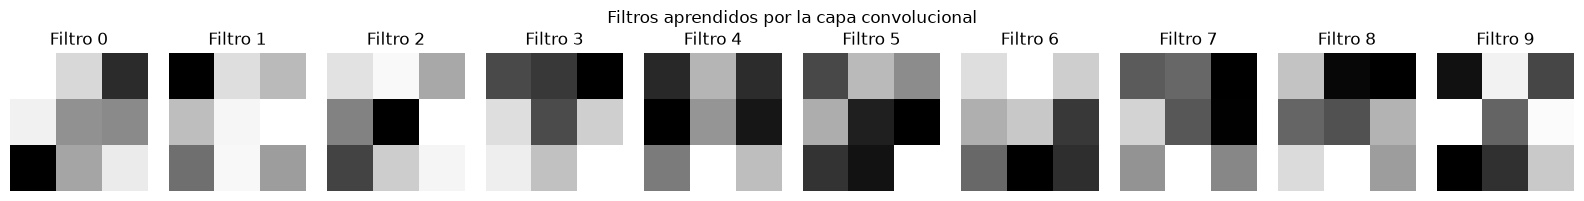

In [26]:
state_dict = model.state_dict()
filters = state_dict['conv1.weight'].detach().cpu().numpy()

fig, axes = plt.subplots(1, 10, figsize=(16, 2))
for i in range(10):
    axes[i].imshow(filters[i, 0], cmap='gray')
    axes[i].set_title(f'Filtro {i}')
    axes[i].axis('off')

plt.suptitle('Filtros aprendidos por la capa convolucional')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'filtros_aprendidos.png', dpi=150)
plt.show()

# Guardamos también los filtros como array NumPy
np.save(OUTPUT_DIR / 'filtros_conv1.npy', filters)

In [27]:
# Evaluación final para obtener etiquetas y predicciones
_, final_accuracy, final_targets, final_predictions = test(model, device, test_datalaoder)

predictions_path = OUTPUT_DIR / 'predicciones_test.csv'
with open(predictions_path, 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['indice', 'etiqueta_real', 'prediccion'])
    for idx, (target, pred) in enumerate(zip(final_targets, final_predictions)):
        writer.writerow([idx, target, pred])

print(f'Predicciones guardadas en: {predictions_path}')
print(f'Precisión final: {100 * final_accuracy:.2f}%')

Test: pérdida media: 0.0301, precisión: 9897/10000 (98.97%)
Predicciones guardadas en: resultados_mnist_convnet_2\predicciones_test.csv
Precisión final: 98.97%


Número de errores en test: 103


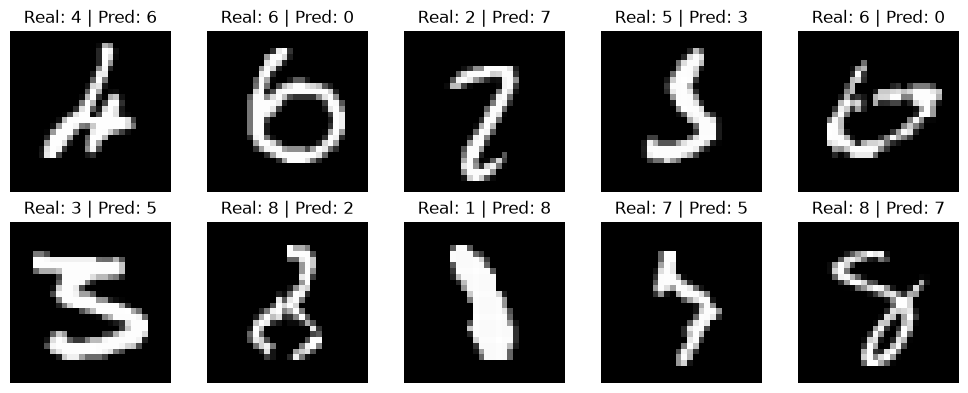

In [28]:
# Localizamos algunos errores de clasificación
errors = [i for i, (t, p) in enumerate(zip(final_targets, final_predictions)) if t != p]
print(f'Número de errores en test: {len(errors)}')

num_errors_to_show = min(10, len(errors))

if num_errors_to_show > 0:
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for ax, idx in zip(axes.ravel(), errors[:num_errors_to_show]):
        image, true_label = test_dataset[idx]
        predicted_label = final_predictions[idx]
        ax.imshow(image.squeeze(), cmap='gray')
        ax.set_title(f'Real: {true_label} | Pred: {predicted_label}')
        ax.axis('off')

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'ejemplos_errores.png', dpi=150)
    plt.show()
else:
    print('No se han encontrado errores en los primeros resultados evaluados.')